# Практическая работа №1. Вариант 13
## Цель работы
Изучить математическое описание линейных дискретных систем и ДПФ периодических последовательностей и последовательностей конечной длины.

## Краткое изложение основных теоретических понятий
Формулы, необходимые для выполнения каждого пункта задания, приведены в самих пунктах.

## Постановка задачи с кратким описанием порядка выполнения работы
1. Вычислить импульсную характеристику и реакции системы, нули и полюсы, построить их карту, АЧХ и ФЧХ.
2. Сформировать сумму гармоник, вычислить ДПФ и ОДПФ, построить спектры, восстановить аналоговый сигнал и проверить равенство Парсеваля.

### Исходные данные
$$\begin{gathered}
Вариант=v=13,\ b_0=0.5+0.02v,\ b_1=b_0(-1)^{v+1}(0.9822+0.0178v),\\
b_2=b_0(0.8+0.2(v\bmod5)),\ a_0=1,\ a_1=(-1)^v(0.7778+0.025v),\ a_2=0.64+0.006v,\\
N_1=v\bmod10+20,\ N_2=v\bmod10+30,\ f_{д1}=1000v,\\
N=64,\ f_{д2}=2000(v\bmod5+1),\ T=1/f_{д2},\\
A_1=1+0.01v,\ A_2=2A_1,\ f_1=f_{д2}/8,\ f_2=1.5f_1.
\end{gathered}$$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams.update({'figure.figsize': (10, 3), 'axes.grid': True})
v = 13
b0 = 0.5 + 0.02*v
b = np.array([b0, b0*(-1)**(v+1)*(0.9822+0.0178*v), b0*(0.8+0.2*(v%5))])
a = np.array([1, (-1)**v*(0.7778+0.025*v), 0.64+0.006*v])
N1, N2, fs1 = v%10+20, v%10+30, 1000*v
N, fs2 = 64, 2000*(v%5+1)
T = 1/fs2
A1, A2 = 1+0.01*v, 2*(1+0.01*v)
f1, f2 = fs2/8, 1.5*fs2/8
print('Параметр              Значение')
for name, value in zip(['b', 'a', 'N1', 'N2', 'fд1, Гц', 'N', 'fд2, Гц', 'T, с', 'A1', 'A2', 'f1, Гц', 'f2, Гц'],
                       [b, a, N1, N2, fs1, N, fs2, T, A1, A2, f1, f2]):
    print(f'{name:<20}  {value}')

Параметр              Значение
b                     [0.76     0.922336 1.064   ]
a                     [ 1.     -1.1028  0.718 ]
N1                    23
N2                    33
fд1, Гц               13000
N                     64
fд2, Гц               8000
T, с                  0.000125
A1                    1.13
A2                    2.26
f1, Гц                1000.0
f2, Гц                1500.0


### Часть 1. Линейная дискретная система
#### 1. Импульсная характеристика
$$H(z)=\frac{Y(z)}{X(z)}=\frac{b_0+b_1z^{-1}+b_2z^{-2}}{1+a_1z^{-1}+a_2z^{-2}},\qquad X(z)=1\ \text{при}\ x[n]=\delta[n].$$
$$h[n]=b_0\delta[n]+b_1\delta[n-1]+b_2\delta[n-2]-a_1h[n-1]-a_2h[n-2],\quad h[n]=0\ (n<0).$$
При $p_1,p_2$ — корнях $z^2+a_1z+a_2=0$:
$$h[0]=b_0,\qquad h[n]=C_1p_1^{n-1}+C_2p_2^{n-1},\ n\ge1,$$
$$d_1=b_1-b_0a_1,\quad d_2=b_2-b_0a_2,\quad C_i=\frac{d_1p_i+d_2}{p_i-p_j},\ i\ne j.$$

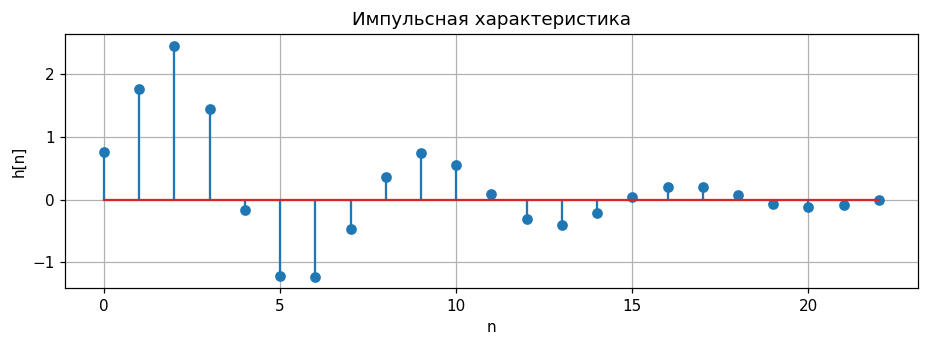

p = [0.5514+0.64339571j 0.5514-0.64339571j]
C = [0.880232-1.15717266j 0.880232+1.15717266j]
Максимальная ошибка аналитической формулы: 6.661338147750939e-16


In [ ]:
impulse = np.zeros(N1)
impulse[0] = 1
h = signal.lfilter(b, a, impulse)
p = np.roots(a)
d1, d2 = b[1]-b[0]*a[1], b[2]-b[0]*a[2]
C = np.array([(d1*p[0]+d2)/(p[0]-p[1]), (d1*p[1]+d2)/(p[1]-p[0])])
ha = np.r_[b[0], np.real(C[0]*p[0]**np.arange(N1-1) + C[1]*p[1]**np.arange(N1-1))]
print('p =', p)
print('C =', C)
print('Максимальная ошибка аналитической формулы:', np.max(np.abs(h-ha)))
plt.stem(np.arange(N1), h)
plt.xlabel('n'); plt.ylabel('h[n]'); plt.title('Импульсная характеристика')
plt.show()

Показаны первые $N_1=23$ отсчёта. Импульсная характеристика рекурсивного звена имеет бесконечную длину и затухает.

#### 2. Реакция по свёртке
$$L=\operatorname{int}(N_2/2)=17,\qquad x[n]=\begin{cases}1,&0\le n<L,\\0,&L\le n<N_2,\end{cases}$$
(L для $16.5$ принято округление вверх)
$$y_1[n]=\sum_{m=0}^{N_1-1}h[m]x[n-m],\qquad N_{y_1}=N_1+N_2-1.$$

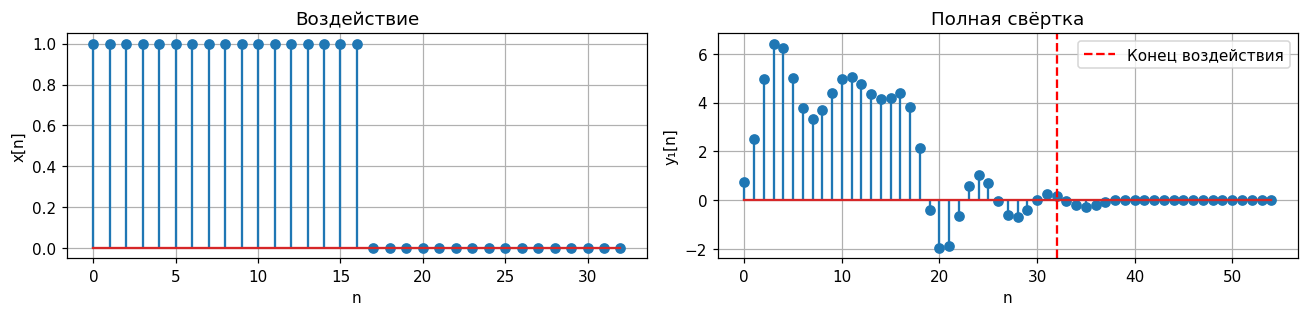

Длина массива x: 33; ненулевая часть: 17; длина свёртки: 55


In [ ]:
L = int(np.floor(N2/2+0.5))
nx = np.arange(N2)
x = (nx < L).astype(float)
y1 = np.convolve(x, h)
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].stem(nx, x); ax[0].set(xlabel='n', ylabel='x[n]', title='Воздействие')
ax[1].stem(np.arange(len(y1)), y1)
ax[1].axvline(N2-1, color='r', linestyle='--', label='Конец воздействия')
ax[1].set(xlabel='n', ylabel='y₁[n]', title='Полная свёртка'); ax[1].legend()
plt.tight_layout(); plt.show()
print(f'Длина массива x: {len(x)}; ненулевая часть: {L}; длина свёртки: {len(y1)}')

Массив воздействия содержит 33 отсчёта, прямоугольный импульс — 17. Свёртка массивов имеет длину $23+33-1=55$ (индексы $0\ldots54$); последние 16 отсчётов нулевые. Ограничение первыми 33 отсчётами задаёт общее окно сравнения с реакцией по разностному уравнению. Полная реакция исходной рекурсивной системы бесконечна.

#### 3. Реакция по разностному уравнению
$$y_2[n]=\sum_{i=0}^{2}b_i x[n-i]-\sum_{k=1}^{2}a_k y_2[n-k].$$
$$y_2[n]=0.76x[n]+0.922336x[n-1]+1.064x[n-2]+1.1028y_2[n-1]-0.718y_2[n-2],$$
$$x[n]=y_2[n]=0\ (n<0),\qquad \varepsilon[n]=y_1[n]-y_2[n].$$

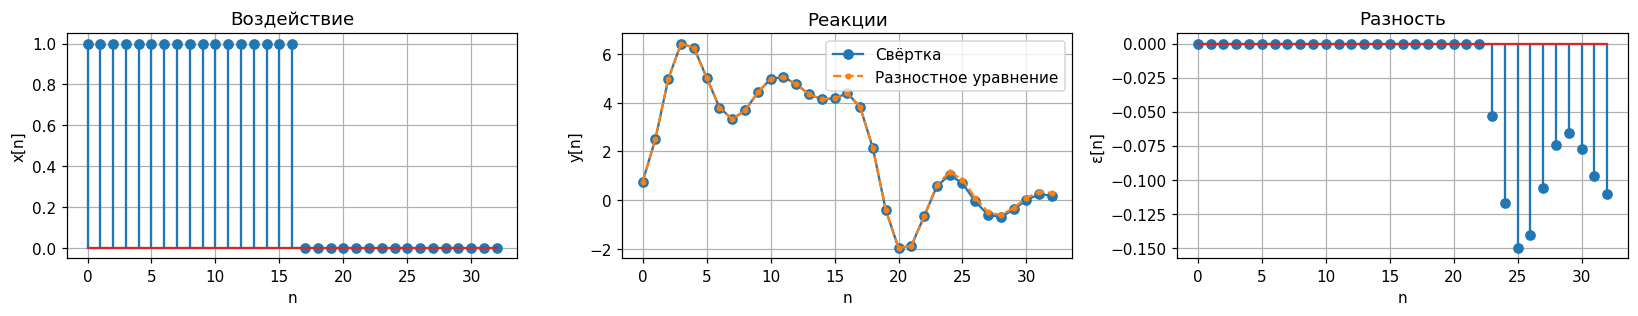

Максимальная разность: 0.1501244358212489
Разность на первых N1 отсчётах: 1.7763568394002505e-15


In [ ]:
y2 = np.zeros(N2)
for n in range(N2):
    for i in range(3):
        if n >= i:
            y2[n] += b[i]*x[n-i]
    for k in range(1, 3):
        if n >= k:
            y2[n] -= a[k]*y2[n-k]
fig, ax = plt.subplots(1, 3, figsize=(15, 3))
ax[0].stem(nx, x); ax[0].set(xlabel='n', ylabel='x[n]', title='Воздействие')
ax[1].plot(nx, y1[:N2], 'o-', label='Свёртка')
ax[1].plot(nx, y2, '.--', label='Разностное уравнение')
ax[1].set(xlabel='n', ylabel='y[n]', title='Реакции'); ax[1].legend()
ax[2].stem(nx, y1[:N2]-y2); ax[2].set(xlabel='n', ylabel='ε[n]', title='Разность')
plt.tight_layout(); plt.show()
print('Максимальная разность:', np.max(np.abs(y1[:N2]-y2)))
print('Разность на первых N1 отсчётах:', np.max(np.abs(y1[:N1]-y2[:N1])))

Воздействие и вычисленная реакция $y_2$ содержат 33 отсчёта. До $n=22$ реакции совпадают с точностью округления; далее свёртка отличается из-за усечения $h[n]$. Реакция рекурсивного звена продолжается и после окончания воздействия.

#### 4. Нули и полюсы
Здесь $R$ — вещественная часть числа $q$, $I$ — его мнимая часть.
$$H(z)=\frac{b_0+b_1z^{-1}+b_2z^{-2}}{1+a_1z^{-1}+a_2z^{-2}}=\frac{b_0z^2+b_1z+b_2}{z^2+a_1z+a_2}.$$
Корни числителя — нули $z_i$, корни знаменателя — полюсы $p_i$.
$$b_0z^2+b_1z+b_2=0,\qquad z^2+a_1z+a_2=0,$$
$$q=R+jI=|q|e^{j\varphi},\qquad |q|=\sqrt{R^2+I^2},\qquad \varphi=\arg q,$$
$$\varphi=\begin{cases}
\operatorname{arctg}(I/R),&R>0,\\
\operatorname{arctg}(I/R)+\pi,&R<0,\ I\ge0,\\
\operatorname{arctg}(I/R)-\pi,&R<0,\ I<0,\\
\pi/2,&R=0,\ I>0,\\
-\pi/2,&R=0,\ I<0.
\end{cases}\qquad \frac{\arg q}{\pi}=\frac{\varphi}{\pi}.$$
Для $q=0$ угол не определён.

In [ ]:
z = np.roots(b)
p = np.roots(a)
print('Тип       R           I          Модуль      arg/π')
for name, roots in [('Нуль', z), ('Полюс', p)]:
    for q in roots:
        print(f'{name:<7} {q.real:11.6f} {q.imag:11.6f} {abs(q):11.6f} {np.angle(q)/np.pi:11.6f}')

Тип       R           I          Модуль      arg/π
Нуль      -0.606800    1.015772    1.183216    0.671406
Нуль      -0.606800   -1.015772    1.183216   -0.671406
Полюс      0.551400    0.643396    0.847349    0.274461
Полюс      0.551400   -0.643396    0.847349   -0.274461


Нули:
$$z_1=-0.60680000+1.01577249j=1.18321596\exp\left(j\,(0.67140644)\pi\right).$$
$$z_2=-0.60680000-1.01577249j=1.18321596\exp\left(j\,(-0.67140644)\pi\right).$$

Полюсы:
$$p_1=0.55140000+0.64339571j=0.84734881\exp\left(j\,(0.27446065)\pi\right).$$
$$p_2=0.55140000-0.64339571j=0.84734881\exp\left(j\,(-0.27446065)\pi\right).$$

Вещественная и мнимая части задают точку на комплексной плоскости; модуль и аргумент — её расстояние до начала координат и угол. Корни образуют комплексно-сопряжённые пары.

Передаточная функция в виде произведения множителей:
$$H(z)=b_0\frac{(1-z_1z^{-1})(1-z_2z^{-1})}{(1-p_1z^{-1})(1-p_2z^{-1})},\qquad z_i=|z_i|e^{j\arg z_i},\quad p_i=|p_i|e^{j\arg p_i}.$$
$$K=b_0=0.76.$$
$$H(z)=0.76\frac{(1-1.183216e^{j0.671406\pi}z^{-1})(1-1.183216e^{-j0.671406\pi}z^{-1})}{(1-0.847349e^{j0.274461\pi}z^{-1})(1-0.847349e^{-j0.274461\pi}z^{-1})}.$$

#### 5. Карта нулей и полюсов
$$R=|q|\cos(\arg q),\quad I=|q|\sin(\arg q),\qquad |p_i|<1.$$

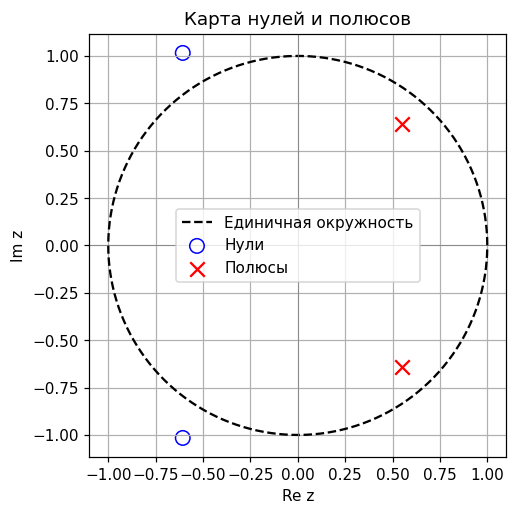

Корни совпадают: True
Система устойчива: True


In [ ]:
z_check, p_check, gain = signal.tf2zpk(b, a)
theta = np.linspace(0, 2*np.pi, 500)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(np.cos(theta), np.sin(theta), 'k--', label='Единичная окружность')
ax.scatter(z_check.real, z_check.imag, facecolors='none', edgecolors='b', s=90, label='Нули')
ax.scatter(p_check.real, p_check.imag, marker='x', color='r', s=90, label='Полюсы')
ax.axhline(0, color='gray', linewidth=0.5); ax.axvline(0, color='gray', linewidth=0.5)
ax.set(xlabel='Re z', ylabel='Im z', title='Карта нулей и полюсов', aspect='equal')
ax.legend(); plt.show()
print('Корни совпадают:', np.allclose(np.sort_complex(z), np.sort_complex(z_check)) and
      np.allclose(np.sort_complex(p), np.sort_complex(p_check)))
print('Система устойчива:', np.all(np.abs(p_check) < 1))

Оба полюса имеют модуль $\sqrt{0.718}\approx0.847349<1$: причинное звено устойчиво. Корни на карте совпадают с результатами п. 4.

#### 6. АЧХ и ФЧХ в нормированных частотах
$$z=e^{j\hat\omega},\qquad H(e^{j\hat\omega})=H(z)\big|_{z=e^{j\hat\omega}}.$$
$$H(e^{j\hat\omega})=\frac{b_0+b_1e^{-j\hat\omega}+b_2e^{-j2\hat\omega}}{1+a_1e^{-j\hat\omega}+a_2e^{-j2\hat\omega}},\qquad A=|H|,\quad\varphi=\arg H.$$

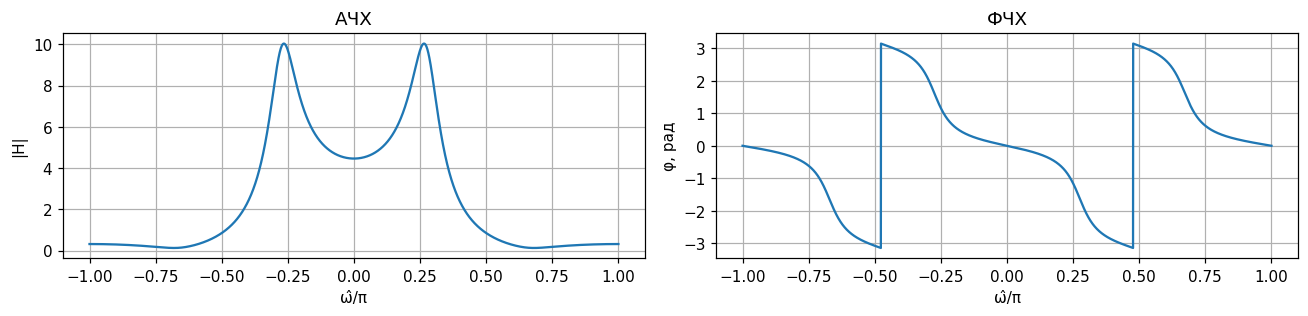

Скачок ФЧХ: ω̂/π ≈ -0.4771, |H| ≈ 1.0764
Скачок ФЧХ: ω̂/π ≈ 0.4766, |H| ≈ 1.0817
|H(0)| = 4.464135; |H(π)| = 0.319648


In [ ]:
w = np.linspace(-np.pi, np.pi, 4097)
w, H = signal.freqz(b, a, worN=w)
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].plot(w/np.pi, abs(H)); ax[0].set(xlabel='ω̂/π', ylabel='|H|', title='АЧХ')
ax[1].plot(w/np.pi, np.angle(H)); ax[1].set(xlabel='ω̂/π', ylabel='φ, рад', title='ФЧХ')
plt.tight_layout(); plt.show()
jumps = np.flatnonzero(abs(np.diff(np.angle(H))) > np.pi)
for i in jumps:
    print(f'Скачок ФЧХ: ω̂/π ≈ {w[i]/np.pi:.4f}, |H| ≈ {abs(H[i]):.4f}')
print(f'|H(0)| = {abs(H[len(H)//2]):.6f}; |H(π)| = {abs(H[-1]):.6f}')

Основная полоса: $-\pi\le\hat\omega<\pi$; для вещественного сигнала достаточно $0\ldots\pi$. Полюсы около $\pm0.27446\pi$ создают подъём АЧХ, нули около $\pm0.67141\pi$ — спад. Высокие частоты подавляются сильнее низких. Нулей на единичной окружности нет, поэтому АЧХ не обращается в нуль и скачков ФЧХ на $\pi$ нет. Видимые скачки равны $2\pi$ и вызваны переходом через границы $\pm\pi$ главного значения фазы; соответствующие ненулевые значения АЧХ выведены выше. В точке $\hat\omega=\pi$ скачка нет.

#### 7. АЧХ и ФЧХ в герцах
$$H_f(f)=H(e^{j2\pi f/f_{д1}})=\frac{b_0+b_1e^{-j2\pi f/f_{д1}}+b_2e^{-j4\pi f/f_{д1}}}{1+a_1e^{-j2\pi f/f_{д1}}+a_2e^{-j4\pi f/f_{д1}}},\qquad A(f)=|H_f(f)|,\quad\varphi(f)=\arg H_f(f).$$
$$f=\frac{\hat\omega f_{д1}}{2\pi},\qquad \hat\omega=\frac{2\pi f}{f_{д1}}.$$

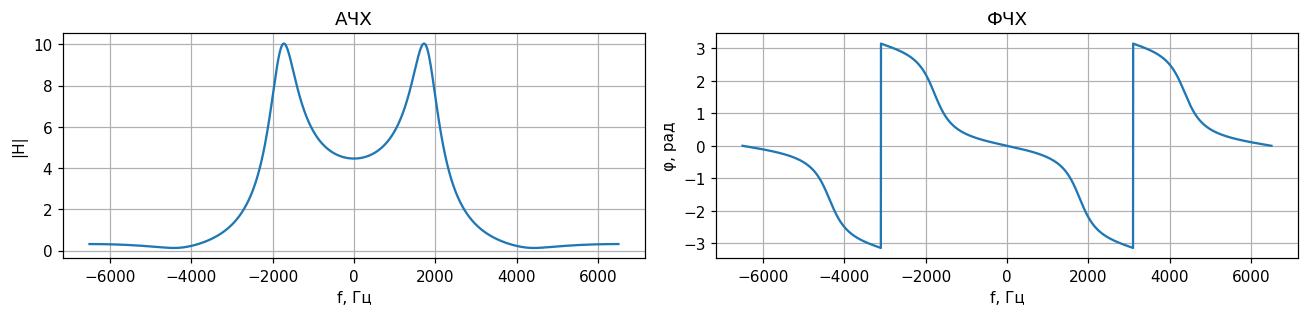

In [ ]:
f = w*fs1/(2*np.pi)
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].plot(f, abs(H)); ax[0].set(xlabel='f, Гц', ylabel='|H|', title='АЧХ')
ax[1].plot(f, np.angle(H)); ax[1].set(xlabel='f, Гц', ylabel='φ, рад', title='ФЧХ')
plt.tight_layout(); plt.show()

При $f_{д1}=13000$ Гц основная полоса: $-6500\le f<6500$ Гц; положительная половина — $0\ldots6500$ Гц. Изменение шкалы не меняет форму характеристик.

### Часть 2. Преобразование Фурье
#### 1. Последовательность на периоде
$$x[n]=A_1\cos(2\pi f_1nT+\pi/4)+A_2\cos(2\pi f_2nT+\pi/8),\quad 0\le n<N.$$
Дискретное время $t_n=nT$, дискретное нормированное время $n=t_n/T$.

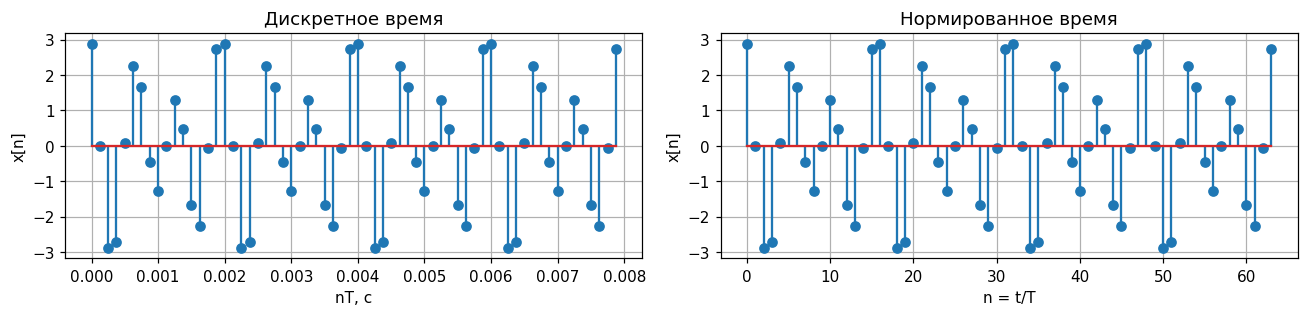

In [ ]:
n = np.arange(N)
tn = n*T
x = A1*np.cos(2*np.pi*f1*tn+np.pi/4) + A2*np.cos(2*np.pi*f2*tn+np.pi/8)
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].stem(tn, x); ax[0].set(xlabel='nT, с', ylabel='x[n]', title='Дискретное время')
ax[1].stem(n, x); ax[1].set(xlabel='n = t/T', ylabel='x[n]', title='Нормированное время')
plt.tight_layout(); plt.show()

#### 2. ОДПФ от ДПФ
$$X[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi kn/N},\qquad \widetilde x[n]=\frac1N\sum_{k=0}^{N-1}X[k]e^{j2\pi kn/N}.$$

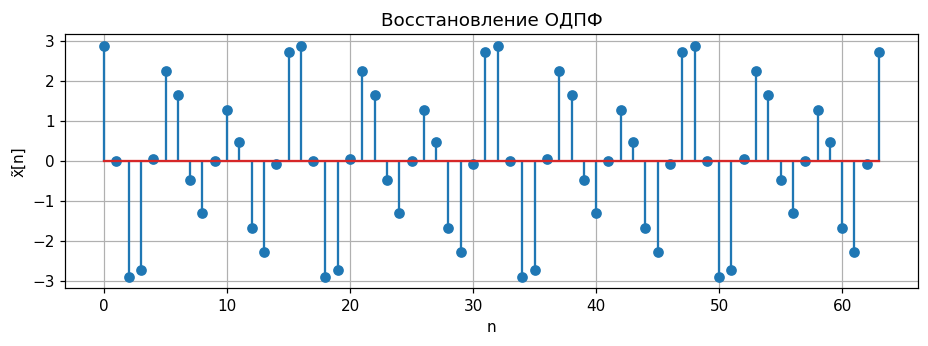

Максимальная ошибка ОДПФ: 1.3322676295501878e-15


In [ ]:
X = np.fft.fft(x)
x_back = np.fft.ifft(X)
plt.stem(n, x_back.real)
plt.xlabel('n'); plt.ylabel('x̃[n]'); plt.title('Восстановление ОДПФ')
plt.show()
print('Максимальная ошибка ОДПФ:', np.max(abs(x_back-x)))

ОДПФ восстанавливает исходные отсчёты с точностью вычислений.

#### 3. Амплитудный и фазовый спектры
$$C[k]=\frac{X[k]}N,\quad A[k]=|C[k]|,\quad\varphi[k]=\arg C[k],\quad\hat\omega_k=\frac{2\pi k}N,\quad f_k=\frac{k f_{д2}}N.$$
Используется двусторонний спектр: амплитуда каждой линии косинуса равна половине его амплитуды. Фаза нулевых коэффициентов не определена.

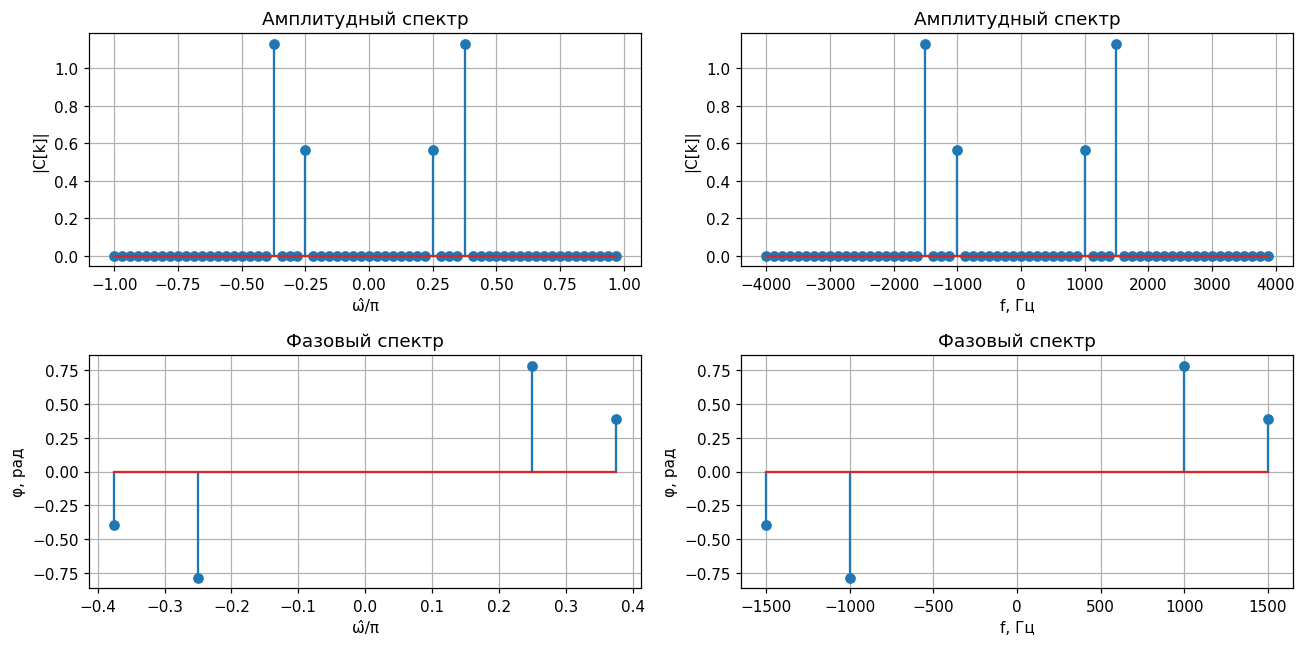

k       f, Гц      ω̂/π       |C|         φ/π
-12     -1500.0   -0.3750    1.130000   -0.1250
 -8     -1000.0   -0.2500    0.565000   -0.2500
  8      1000.0    0.2500    0.565000    0.2500
 12      1500.0    0.3750    1.130000    0.1250


In [ ]:
k = np.arange(-N//2, N//2)
Xa = np.fft.fftshift(X)
Cspec = Xa/N
amp = abs(Cspec)
mask = amp > 1e-10
phase = np.angle(Cspec)
wk = 2*np.pi*k/N
fk = k*fs2/N
fig, ax = plt.subplots(2, 2, figsize=(12, 6))
for col, (axis, label) in enumerate([(wk/np.pi, 'ω̂/π'), (fk, 'f, Гц')]):
    ax[0, col].stem(axis, amp); ax[0, col].set(xlabel=label, ylabel='|C[k]|', title='Амплитудный спектр')
    ax[1, col].stem(axis[mask], phase[mask]); ax[1, col].set(xlabel=label, ylabel='φ, рад', title='Фазовый спектр')
plt.tight_layout(); plt.show()
print('k       f, Гц      ω̂/π       |C|         φ/π')
for i in np.flatnonzero(mask):
    print(f'{k[i]:3d} {fk[i]:11.1f} {wk[i]/np.pi:9.4f} {amp[i]:11.6f} {phase[i]/np.pi:9.4f}')

$f_{д2}=8000$ Гц, $f_1=1000$ Гц, $f_2=1500$ Гц; частотный шаг $125$ Гц. Линии расположены при $k=\pm8,\pm12$, или $\hat\omega=\pm\pi/4,\pm3\pi/8$. Их амплитуды $0.565$ и $1.13$, фазы на положительных частотах $\pi/4$ и $\pi/8$, на отрицательных — противоположные. Спектрального растекания нет: на 64 отсчётах укладываются 8 и 12 периодов гармоник.

#### 4. ДПФ конечной последовательности
$$X_{\mathrm{кон}}[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi kn/N}=X[k],\qquad |X_{\mathrm{кон}}[k]|=N|C[k]|.$$

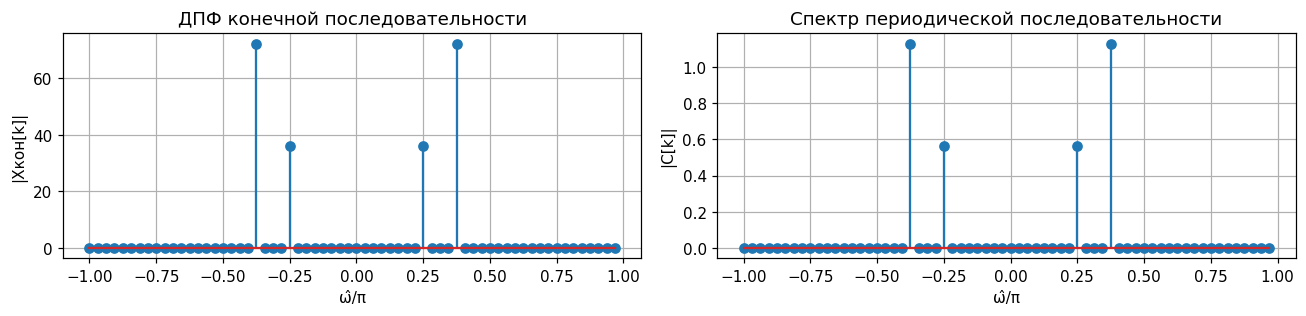

Ошибка соотношения |Xкон| = N|C|: 0.0


In [ ]:
X_finite = np.fft.fftshift(np.fft.fft(x, n=N))
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].stem(wk/np.pi, abs(X_finite)); ax[0].set(xlabel='ω̂/π', ylabel='|Xкон[k]|', title='ДПФ конечной последовательности')
ax[1].stem(wk/np.pi, amp); ax[1].set(xlabel='ω̂/π', ylabel='|C[k]|', title='Спектр периодической последовательности')
plt.tight_layout(); plt.show()
print('Ошибка соотношения |Xкон| = N|C|:', np.max(abs(abs(X_finite)-N*amp)))

Положения линий совпадают; модуль ДПФ конечной последовательности в 64 раза больше амплитудного спектра периодической последовательности.

#### 5. Восстановление аналогового сигнала
$$X_a[k]=\begin{cases}X[N+k],&-N/2\le k<0,\\X[k],&0\le k<N/2,\end{cases}$$
$$x_{\mathrm{восст}}(t)=\frac1N\sum_{k=-N/2}^{N/2-1}X_a[k]e^{j2\pi kt/(NT)},\qquad t\in[0,(N-1)T],\quad\Delta t=0.25T,$$
$$x_{\mathrm{исх}}(t)=A_1\cos(2\pi f_1t+\pi/4)+A_2\cos(2\pi f_2t+\pi/8),\qquad |C_a[k]|=|X_a[k]|/N.$$

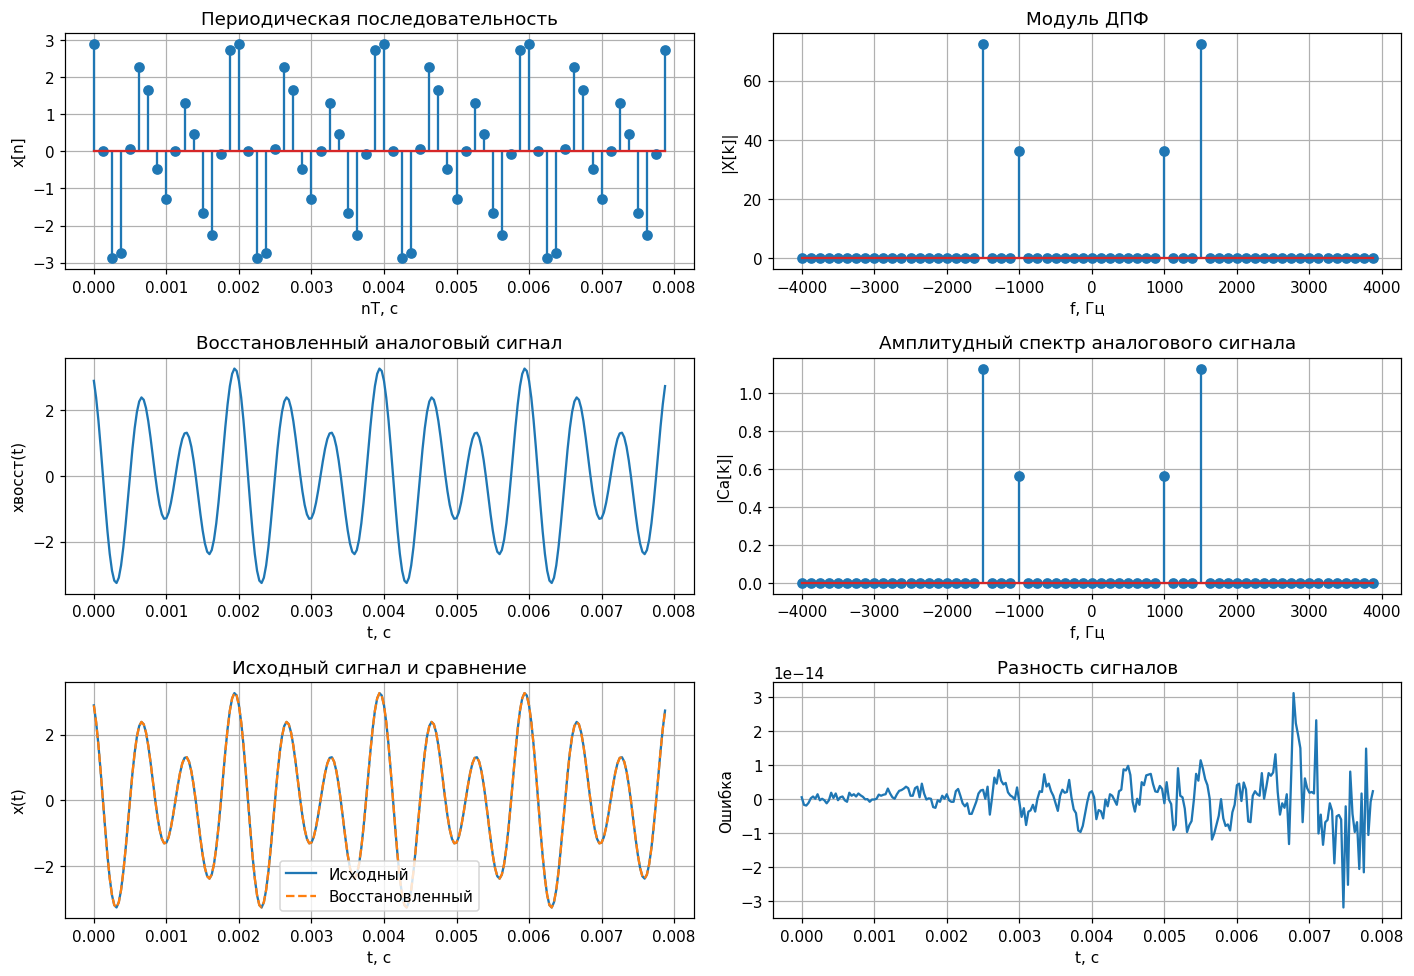

Максимальная ошибка восстановления: 3.197768210527331e-14


In [ ]:
t = np.arange(4*(N-1)+1)*T/4
x_rec = np.sum(Xa[:, None]*np.exp(1j*2*np.pi*k[:, None]*t/(N*T)), axis=0)/N
x_original = A1*np.cos(2*np.pi*f1*t+np.pi/4) + A2*np.cos(2*np.pi*f2*t+np.pi/8)
fig, ax = plt.subplots(3, 2, figsize=(13, 9))
ax[0, 0].stem(tn, x); ax[0, 0].set(xlabel='nT, с', ylabel='x[n]', title='Периодическая последовательность')
ax[0, 1].stem(fk, abs(Xa)); ax[0, 1].set(xlabel='f, Гц', ylabel='|X[k]|', title='Модуль ДПФ')
ax[1, 0].plot(t, x_rec.real); ax[1, 0].set(xlabel='t, с', ylabel='xвосст(t)', title='Восстановленный аналоговый сигнал')
ax[1, 1].stem(fk, abs(Xa)/N); ax[1, 1].set(xlabel='f, Гц', ylabel='|Ca[k]|', title='Амплитудный спектр аналогового сигнала')
ax[2, 0].plot(t, x_original, label='Исходный')
ax[2, 0].plot(t, x_rec.real, '--', label='Восстановленный')
ax[2, 0].set(xlabel='t, с', ylabel='x(t)', title='Исходный сигнал и сравнение'); ax[2, 0].legend()
ax[2, 1].plot(t, x_rec.real-x_original)
ax[2, 1].set(xlabel='t, с', ylabel='Ошибка', title='Разность сигналов')
plt.tight_layout(); plt.show()
print('Максимальная ошибка восстановления:', np.max(abs(x_rec-x_original)))

#### 6. Связь спектров и сравнение сигналов
$$f_{\max}=\max(f_1,f_2),\qquad f_{\max}<\frac{f_{д2}}2.$$
$$|C_a[k]|=\frac{|X_a[k]|}{N},\qquad f_k=\frac{k}{NT},\qquad \max(f_1,f_2)=1500<\frac{f_{д2}}2=4000\ \text{Гц}.$$
Спектр аналогового периодического сигнала содержит линии при $\pm1000$ и $\pm1500$ Гц с амплитудами $0.565$ и $1.13$. Исходный и восстановленный сигналы визуально совпадают: обе гармоники ниже частоты Найквиста и попадают в узлы ДПФ; оставшаяся ошибка обусловлена округлением.
#### 7. Равенство Парсеваля
$$\sum_{n=0}^{N-1}|x[n]|^2=\frac1N\sum_{k=0}^{N-1}|X[k]|^2,\qquad P=\frac1N\sum_n|x[n]|^2=\sum_k|C[k]|^2.$$

In [ ]:
E_time = np.sum(abs(x)**2)
E_freq = np.sum(abs(X)**2)/N
print(f'Сумма во времени: {E_time:.12f}')
print(f'Сумма по спектру: {E_freq:.12f}')
print(f'Абсолютная разность: {abs(E_time-E_freq):.3e}')
print(f'Средняя мощность: {E_time/N:.12f}')
print('Равенство выполнено:', np.isclose(E_time, E_freq))

Сумма во времени: 204.304000000000
Сумма по спектру: 204.304000000000
Абсолютная разность: 2.842e-14
Средняя мощность: 3.192250000000
Равенство выполнено: True


Равенство выражает сохранение энергии при переходе между временным и частотным представлениями; деление на $N$ даёт среднюю мощность периодической последовательности.


## Общий вывод по проделанной работе
Рекурсивное звено устойчиво и сильнее подавляет высокие частоты. Разностное уравнение и свёртка дают одинаковую реакцию до влияния усечения импульсной характеристики. ДПФ выделяет гармоники 1000 и 1500 Гц; ОДПФ и интерполяция восстанавливают отсчёты и аналоговый сигнал с точностью вычислений. Равенство Парсеваля выполнено.